# Final Project Part 2 
## Jake Brand and Roy Marshall
### Introduction
Use this notebook as a guide for ingesting data and performing exploratory data anaylsis (EDA).  The overall goal is to familiarize yourself with some data you have no previous experience using.  Remember, every problem is different, so this is **not** a template.

We will use the cell below to import any necessary Python packages.  We will need to re-run that cell if we add a package.

Install packages (if necessary)

In [1]:
import sys
!python -m pip install pandas
!python -m pip install requests
!python -m pip install seaborn


[notice] A new release of pip is available: 25.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


  Using cached requests-2.34.2-py3-none-any.whl.metadata (4.8 kB)
  Using cached idna-3.20-py3-none-any.whl.metadata (7.2 kB)
  Using cached urllib3-2.8.0-py3-none-any.whl.metadata (7.4 kB)
  Using cached certifi-2026.7.22-py3-none-any.whl.metadata (2.5 kB)
Using cached requests-2.34.2-py3-none-any.whl (73 kB)
Using cached idna-3.20-py3-none-any.whl (69 kB)
Using cached urllib3-2.8.0-py3-none-any.whl (135 kB)
Using cached certifi-2026.7.22-py3-none-any.whl (136 kB)

   ---------------------------------------- 0/5 [urllib3]
   ---------------------------------------- 0/5 [urllib3]
   ---------------------------------------- 0/5 [urllib3]
   ---------------------------------------- 0/5 [urllib3]
   ---------------------------------------- 0/5 [urllib3]
   ---------------------------------------- 0/5 [urllib3]
   ---------------------------------------- 0/5 [urllib3]
   -------- ------------------------------- 1/5 [idna]
   -------- ------------------------------- 1/5 [idna]
   -------- -


[notice] A new release of pip is available: 25.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
  Using cached matplotlib-3.11.2-cp313-cp313-win_amd64.whl.metadata (80 kB)
  Using cached contourpy-1.4.0-cp313-cp313-win_amd64.whl.metadata (3.8 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached kiwisolver-1.5.1-cp313-cp313-win_amd64.whl.metadata (5.2 kB)
  Using cached pillow-12.3.0-cp313-cp313-win_amd64.whl.metadata (9.3 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)
Using cached matplotlib-3.11.2-cp313-cp313-win_amd64.whl (9.3 MB)
Using cached contourpy-1.4.0-cp313-cp313-win_amd64.whl (234 kB)
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
   ---------------------------------------- 0.0/2.5 MB ? eta -:--:--
   ---------------------------------------- 2.5/2.5 MB 12.4 MB/s eta 0:00:00
Using cached kiwisolver-1.5.1-cp313-cp313-win_amd64.whl (70 kB)
Using cached pillow-12.3.0-cp313-cp313-win_amd64.whl (7.2 


[notice] A new release of pip is available: 25.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [6]:
import pandas as pd
import seaborn

In [16]:
API_KEY = "DsOW3csCqK5UFkFUpamdGMIRWVA4T3ra"
import requests
url = "https://api.massive.com/v2/aggs/ticker/AAPL/range/1/day/2025-01-01/2025-12-31"

response = requests.get(
    url,
    params={"apiKey": API_KEY}
)

response.raise_for_status()
data = response.json()

df_stock = pd.DataFrame(data["results"])

df_stock.head()




,v,vw,o,c,h,l,t,n
0,55740731.0,244.3303,248.93,243.85,249.1000,241.8201,1735794000000,685448
1,40244114.0,243.0805,243.36,243.36,244.1800,241.8900,1735880400000,493786
2,45045571.0,245.1726,244.31,245.00,247.3300,243.2000,1736139600000,493920
3,40855960.0,242.9459,242.98,242.21,245.5500,241.3500,1736226000000,462887
4,37628940.0,242.2995,241.92,242.70,243.7123,240.0500,1736312400000,406916


Let's read in the data.  First, take a look at the file itself so you can see the format.  Then use an appropriate method to read the file.  Once we have a dataframe, we can access the *shape* property to see what we're working with.

The data set is relatively large...rather than distributing it with the notebook, fetch it from Google Drive.

In [3]:
import requests
url = 'https://drive.google.com/uc?export=download&id=1brSAVG12ft34t3wO4jfNaJYUReMW-J2c'
response = requests.get(url, headers={'User-Agent': f'requests/{requests.__version__}'})
with open('jc1.txt', 'wb') as f:
    f.write(response.content)

In [ ]:
df_orig = pd.read_csv('jc1.txt')
df_orig.shape

(3625, 16)

Let's look at the first few rows.

In [5]:
df_orig.head()

,_input,_num,_widgetName,_source,_resultNumber,_pageUrl,game_number,bio1,bio2,bio3,contestant1_name,contestant1_score,contestant2_name,contestant2_score,contestant3_name,contestant3_score
0,NaN,1,Jeopardy_Winners,Jeopardy_Winners,1,http://www.j-archive.com/showgame.php?game_id=...,Show #5883 - Wednesday March 24 2010,Derek Honoré an attorney from Inglewood Califo...,Tatiana Walton a graphic designer from Cutler ...,Regina Robbins an arts teacher from New York N...,Regina,$19401,Tatiana,$7100,Derek,$11900
1,NaN,2,Jeopardy_Winners,Jeopardy_Winners,2,http://www.j-archive.com/showgame.php?game_id=...,Show #6756 - Monday January 20 2014,Jon McGuire a software-development manager fro...,Blake Perkins an environmental scientist from ...,Sarah McNitt a study abroad adviser originally...,Sarah,$20199,Blake,$0,Jon,$8380
2,NaN,3,Jeopardy_Winners,Jeopardy_Winners,3,http://www.j-archive.com/showgame.php?game_id=...,Show #5754 - Thursday September 24 2009,Christopher Nold an economics and film studies...,Rachel Landau a museum night security guard fr...,Joann Mariani a high school English teacher fr...,Joann,$99,Rachel,NaN,Christopher,$23000
3,NaN,4,Jeopardy_Winners,Jeopardy_Winners,4,http://www.j-archive.com/showgame.php?game_id=900,Show #314 - Thursday November 21 1985,Jerry Frankel a musician and a composer origin...,Bruce Fauman a university administrator and pr...,Steve Rogitz a letter carrier from Gardena Cal...,Steve,$4500,Bruce,$4300,Jerry,$6100
4,NaN,5,Jeopardy_Winners,Jeopardy_Winners,5,http://www.j-archive.com/showgame.php?game_id=550,Show #4846 - Monday October 10 2005,Andrew Vogl from Yonkers New York,Madeline Suchard from Placentia California,Pranita Ramakrishnan from Centreville Virginia,Pranita,NaN,Madeline,$20401,Andrew,$20399


In [6]:
type(df_orig.loc[0, 'contestant1_score'])

str

Now let's look at the data types and see if there are missing values.  The `.info()` method is a good tool for this.

In [7]:
df_orig.info()

<class 'pandas.DataFrame'>
RangeIndex: 3625 entries, 0 to 3624
Data columns (total 16 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   _input             0 non-null      float64
 1   _num               3625 non-null   int64  
 2   _widgetName        3625 non-null   str    
 3   _source            3625 non-null   str    
 4   _resultNumber      3625 non-null   int64  
 5   _pageUrl           3625 non-null   str    
 6   game_number        3625 non-null   str    
 7   bio1               3625 non-null   str    
 8   bio2               3625 non-null   str    
 9   bio3               3625 non-null   str    
 10  contestant1_name   3495 non-null   str    
 11  contestant1_score  3466 non-null   str    
 12  contestant2_name   3495 non-null   str    
 13  contestant2_score  3442 non-null   str    
 14  contestant3_name   3495 non-null   str    
 15  contestant3_score  3427 non-null   str    
dtypes: float64(1), int64(2), str(13)
me

Let's examine the missing values and decide what we'd like to do with them.  It can be smart to keep a copy of the original dataframe in case we need to go back to it.

In [8]:
df = df_orig[df_orig['contestant1_name'].notnull()]
df.head()

,_input,_num,_widgetName,_source,_resultNumber,_pageUrl,game_number,bio1,bio2,bio3,contestant1_name,contestant1_score,contestant2_name,contestant2_score,contestant3_name,contestant3_score
0,NaN,1,Jeopardy_Winners,Jeopardy_Winners,1,http://www.j-archive.com/showgame.php?game_id=...,Show #5883 - Wednesday March 24 2010,Derek Honoré an attorney from Inglewood Califo...,Tatiana Walton a graphic designer from Cutler ...,Regina Robbins an arts teacher from New York N...,Regina,$19401,Tatiana,$7100,Derek,$11900
1,NaN,2,Jeopardy_Winners,Jeopardy_Winners,2,http://www.j-archive.com/showgame.php?game_id=...,Show #6756 - Monday January 20 2014,Jon McGuire a software-development manager fro...,Blake Perkins an environmental scientist from ...,Sarah McNitt a study abroad adviser originally...,Sarah,$20199,Blake,$0,Jon,$8380
2,NaN,3,Jeopardy_Winners,Jeopardy_Winners,3,http://www.j-archive.com/showgame.php?game_id=...,Show #5754 - Thursday September 24 2009,Christopher Nold an economics and film studies...,Rachel Landau a museum night security guard fr...,Joann Mariani a high school English teacher fr...,Joann,$99,Rachel,NaN,Christopher,$23000
3,NaN,4,Jeopardy_Winners,Jeopardy_Winners,4,http://www.j-archive.com/showgame.php?game_id=900,Show #314 - Thursday November 21 1985,Jerry Frankel a musician and a composer origin...,Bruce Fauman a university administrator and pr...,Steve Rogitz a letter carrier from Gardena Cal...,Steve,$4500,Bruce,$4300,Jerry,$6100
4,NaN,5,Jeopardy_Winners,Jeopardy_Winners,5,http://www.j-archive.com/showgame.php?game_id=550,Show #4846 - Monday October 10 2005,Andrew Vogl from Yonkers New York,Madeline Suchard from Placentia California,Pranita Ramakrishnan from Centreville Virginia,Pranita,NaN,Madeline,$20401,Andrew,$20399


In [9]:
df.info()

<class 'pandas.DataFrame'>
Index: 3495 entries, 0 to 3624
Data columns (total 16 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   _input             0 non-null      float64
 1   _num               3495 non-null   int64  
 2   _widgetName        3495 non-null   str    
 3   _source            3495 non-null   str    
 4   _resultNumber      3495 non-null   int64  
 5   _pageUrl           3495 non-null   str    
 6   game_number        3495 non-null   str    
 7   bio1               3495 non-null   str    
 8   bio2               3495 non-null   str    
 9   bio3               3495 non-null   str    
 10  contestant1_name   3495 non-null   str    
 11  contestant1_score  3466 non-null   str    
 12  contestant2_name   3495 non-null   str    
 13  contestant2_score  3442 non-null   str    
 14  contestant3_name   3495 non-null   str    
 15  contestant3_score  3427 non-null   str    
dtypes: float64(1), int64(2), str(13)
memory 

We might be interested in final score data, but there's a problem.  Let's handle with that.

In [10]:
cols = ['contestant1_score', 'contestant2_score', 'contestant3_score']
df[cols] = df[cols].apply(lambda x: x.str.replace('$', '', regex=False))
df[cols] = df[cols].apply(pandas.to_numeric)
df.info()

<class 'pandas.DataFrame'>
Index: 3495 entries, 0 to 3624
Data columns (total 16 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   _input             0 non-null      float64
 1   _num               3495 non-null   int64  
 2   _widgetName        3495 non-null   str    
 3   _source            3495 non-null   str    
 4   _resultNumber      3495 non-null   int64  
 5   _pageUrl           3495 non-null   str    
 6   game_number        3495 non-null   str    
 7   bio1               3495 non-null   str    
 8   bio2               3495 non-null   str    
 9   bio3               3495 non-null   str    
 10  contestant1_name   3495 non-null   str    
 11  contestant1_score  3466 non-null   float64
 12  contestant2_name   3495 non-null   str    
 13  contestant2_score  3442 non-null   float64
 14  contestant3_name   3495 non-null   str    
 15  contestant3_score  3427 non-null   float64
dtypes: float64(4), int64(2), str(10)
memory 

Now let's see how those score values are distributed.

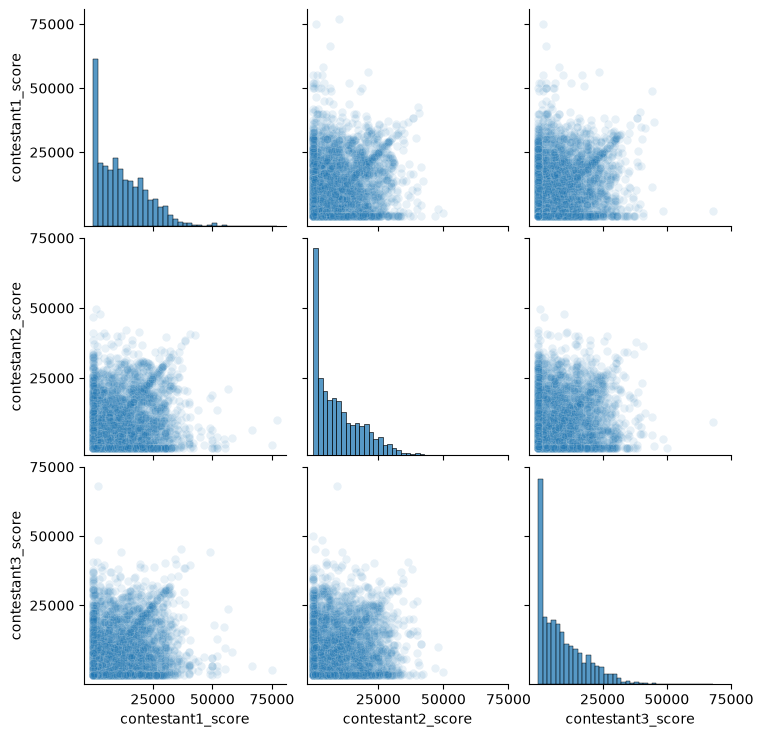

In [11]:
g = seaborn.pairplot(df[cols], plot_kws=dict(alpha=0.1))
g.set(xticks=[25000, 50000, 75000], yticks=[25000, 50000, 75000])

What question(s) can we ask (and answer) with this data?  Let's figure out how often Contestant 1 wins.  First we'll create a new column for the winning score.

In [12]:
df['high score'] = df[cols].max(axis=1)

In [13]:
df

,_input,_num,_widgetName,_source,_resultNumber,_pageUrl,game_number,bio1,bio2,bio3,contestant1_name,contestant1_score,contestant2_name,contestant2_score,contestant3_name,contestant3_score,high score
0,NaN,1,Jeopardy_Winners,Jeopardy_Winners,1,http://www.j-archive.com/showgame.php?game_id=...,Show #5883 - Wednesday March 24 2010,Derek Honoré an attorney from Inglewood Califo...,Tatiana Walton a graphic designer from Cutler ...,Regina Robbins an arts teacher from New York N...,Regina,19401.0,Tatiana,7100.0,Derek,11900.0,19401.0
1,NaN,2,Jeopardy_Winners,Jeopardy_Winners,2,http://www.j-archive.com/showgame.php?game_id=...,Show #6756 - Monday January 20 2014,Jon McGuire a software-development manager fro...,Blake Perkins an environmental scientist from ...,Sarah McNitt a study abroad adviser originally...,Sarah,20199.0,Blake,0.0,Jon,8380.0,20199.0
2,NaN,3,Jeopardy_Winners,Jeopardy_Winners,3,http://www.j-archive.com/showgame.php?game_id=...,Show #5754 - Thursday September 24 2009,Christopher Nold an economics and film studies...,Rachel Landau a museum night security guard fr...,Joann Mariani a high school English teacher fr...,Joann,99.0,Rachel,NaN,Christopher,23000.0,23000.0
3,NaN,4,Jeopardy_Winners,Jeopardy_Winners,4,http://www.j-archive.com/showgame.php?game_id=900,Show #314 - Thursday November 21 1985,Jerry Frankel a musician and a composer origin...,Bruce Fauman a university administrator and pr...,Steve Rogitz a letter carrier from Gardena Cal...,Steve,4500.0,Bruce,4300.0,Jerry,6100.0,6100.0
4,NaN,5,Jeopardy_Winners,Jeopardy_Winners,5,http://www.j-archive.com/showgame.php?game_id=550,Show #4846 - Monday October 10 2005,Andrew Vogl from Yonkers New York,Madeline Suchard from Placentia California,Pranita Ramakrishnan from Centreville Virginia,Pranita,NaN,Madeline,20401.0,Andrew,20399.0,20401.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3619,NaN,3620,Jeopardy_Winners,Jeopardy_Winners,3620,http://www.j-archive.com/showgame.php?game_id=804,Show #4945 - Friday February 24 2006,Dave Lombard a program manager from Houston Texas,Trevor Pritchard a freelance writer from Toron...,Bonnie Clair an attorney from St. Louis Missou...,Bonnie,11150.0,Trevor,4201.0,Dave,200.0,11150.0
3621,NaN,3622,Jeopardy_Winners,Jeopardy_Winners,3622,http://www.j-archive.com/showgame.php?game_id=...,Show #5045 - Friday July 14 2006,Bruce Lin a research scientist originally from...,Lisa Llanes-Simpson a social worker and notary...,Eric Allen a video game merchandiser from Birm...,Eric,NaN,Lisa,100.0,Bruce,9599.0,9599.0
3622,NaN,3623,Jeopardy_Winners,Jeopardy_Winners,3623,http://www.j-archive.com/showgame.php?game_id=...,Show #4111 - Monday June 17 2002,Jim Baer a project coordinator from Mount Laur...,Shelley Hagan a planning analyst from Baraboo ...,Brian O'Riordan an audio/visual manager from S...,Brian,1800.0,Shelley,1000.0,Jim,9799.0,9799.0
3623,NaN,3624,Jeopardy_Winners,Jeopardy_Winners,3624,http://www.j-archive.com/showgame.php?game_id=...,Show #3171 - Monday May 18 1998,Karen Burke a registered dietician from Naperv...,Mark Quigg a family doctor from Collingwood On...,Trudy Ring an editor and writer from Burbank C...,Trudy,15401.0,Mark,11801.0,Karen,9400.0,15401.0


Now we create a Boolean column that will be True when Contestant 1's score is the same as the High Score.

In [14]:
df['c1 wins'] = df['contestant1_score'] == df['high score']

In [15]:
df

,_input,_num,_widgetName,_source,_resultNumber,_pageUrl,game_number,bio1,bio2,bio3,contestant1_name,contestant1_score,contestant2_name,contestant2_score,contestant3_name,contestant3_score,high score,c1 wins
0,NaN,1,Jeopardy_Winners,Jeopardy_Winners,1,http://www.j-archive.com/showgame.php?game_id=...,Show #5883 - Wednesday March 24 2010,Derek Honoré an attorney from Inglewood Califo...,Tatiana Walton a graphic designer from Cutler ...,Regina Robbins an arts teacher from New York N...,Regina,19401.0,Tatiana,7100.0,Derek,11900.0,19401.0,True
1,NaN,2,Jeopardy_Winners,Jeopardy_Winners,2,http://www.j-archive.com/showgame.php?game_id=...,Show #6756 - Monday January 20 2014,Jon McGuire a software-development manager fro...,Blake Perkins an environmental scientist from ...,Sarah McNitt a study abroad adviser originally...,Sarah,20199.0,Blake,0.0,Jon,8380.0,20199.0,True
2,NaN,3,Jeopardy_Winners,Jeopardy_Winners,3,http://www.j-archive.com/showgame.php?game_id=...,Show #5754 - Thursday September 24 2009,Christopher Nold an economics and film studies...,Rachel Landau a museum night security guard fr...,Joann Mariani a high school English teacher fr...,Joann,99.0,Rachel,NaN,Christopher,23000.0,23000.0,False
3,NaN,4,Jeopardy_Winners,Jeopardy_Winners,4,http://www.j-archive.com/showgame.php?game_id=900,Show #314 - Thursday November 21 1985,Jerry Frankel a musician and a composer origin...,Bruce Fauman a university administrator and pr...,Steve Rogitz a letter carrier from Gardena Cal...,Steve,4500.0,Bruce,4300.0,Jerry,6100.0,6100.0,False
4,NaN,5,Jeopardy_Winners,Jeopardy_Winners,5,http://www.j-archive.com/showgame.php?game_id=550,Show #4846 - Monday October 10 2005,Andrew Vogl from Yonkers New York,Madeline Suchard from Placentia California,Pranita Ramakrishnan from Centreville Virginia,Pranita,NaN,Madeline,20401.0,Andrew,20399.0,20401.0,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3619,NaN,3620,Jeopardy_Winners,Jeopardy_Winners,3620,http://www.j-archive.com/showgame.php?game_id=804,Show #4945 - Friday February 24 2006,Dave Lombard a program manager from Houston Texas,Trevor Pritchard a freelance writer from Toron...,Bonnie Clair an attorney from St. Louis Missou...,Bonnie,11150.0,Trevor,4201.0,Dave,200.0,11150.0,True
3621,NaN,3622,Jeopardy_Winners,Jeopardy_Winners,3622,http://www.j-archive.com/showgame.php?game_id=...,Show #5045 - Friday July 14 2006,Bruce Lin a research scientist originally from...,Lisa Llanes-Simpson a social worker and notary...,Eric Allen a video game merchandiser from Birm...,Eric,NaN,Lisa,100.0,Bruce,9599.0,9599.0,False
3622,NaN,3623,Jeopardy_Winners,Jeopardy_Winners,3623,http://www.j-archive.com/showgame.php?game_id=...,Show #4111 - Monday June 17 2002,Jim Baer a project coordinator from Mount Laur...,Shelley Hagan a planning analyst from Baraboo ...,Brian O'Riordan an audio/visual manager from S...,Brian,1800.0,Shelley,1000.0,Jim,9799.0,9799.0,False
3623,NaN,3624,Jeopardy_Winners,Jeopardy_Winners,3624,http://www.j-archive.com/showgame.php?game_id=...,Show #3171 - Monday May 18 1998,Karen Burke a registered dietician from Naperv...,Mark Quigg a family doctor from Collingwood On...,Trudy Ring an editor and writer from Burbank C...,Trudy,15401.0,Mark,11801.0,Karen,9400.0,15401.0,True


In [16]:
df.describe(include='all')


,_input,_num,_widgetName,_source,_resultNumber,_pageUrl,game_number,bio1,bio2,bio3,contestant1_name,contestant1_score,contestant2_name,contestant2_score,contestant3_name,contestant3_score,high score,c1 wins
count,0.0,3495.000000,3495,3495,3495.000000,3495,3495,3495,3495,3495,3495,3466.000000,3495,3442.000000,3495,3427.000000,3495.000000,3495
unique,NaN,NaN,1,1,NaN,3495,3495,3365,3369,3393,759,NaN,1114,NaN,1067,NaN,NaN,2
top,NaN,NaN,Jeopardy_Winners,Jeopardy_Winners,NaN,http://www.j-archive.com/showgame.php?game_id=...,Show #5883 - Wednesday March 24 2010,Kara Spak a newspaper reporter from Chicago Il...,Mike Blumenfeld a network administrator from M...,Kermin Fleming a junior at Carnegie Mellon Uni...,Ken,NaN,Tom,NaN,John,NaN,NaN,False
freq,NaN,NaN,3495,3495,NaN,1,1,3,3,4,81,NaN,45,NaN,60,NaN,NaN,1947
mean,NaN,1793.295279,NaN,NaN,1793.295279,NaN,NaN,NaN,NaN,NaN,NaN,12173.881708,NaN,9410.121732,NaN,9214.537205,17844.598856,NaN
std,NaN,1038.233873,NaN,NaN,1038.233873,NaN,NaN,NaN,NaN,NaN,NaN,10438.434722,NaN,8965.575114,NaN,8893.225177,9354.529647,NaN
min,NaN,1.000000,NaN,NaN,1.000000,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,NaN,0.000000,NaN,0.000000,0.000000,NaN
25%,NaN,895.500000,NaN,NaN,895.500000,NaN,NaN,NaN,NaN,NaN,NaN,3300.000000,NaN,1600.000000,NaN,1600.000000,10600.000000,NaN
50%,NaN,1788.000000,NaN,NaN,1788.000000,NaN,NaN,NaN,NaN,NaN,NaN,10300.000000,NaN,7153.500000,NaN,6999.000000,17000.000000,NaN
75%,NaN,2687.500000,NaN,NaN,2687.500000,NaN,NaN,NaN,NaN,NaN,NaN,19199.750000,NaN,15200.000000,NaN,14475.000000,24000.000000,NaN


In [17]:
sum(df['c1 wins']) / len(df)

0.4429184549356223

It's interesting that the minimum High Score is sometimes zero.  I wonder how many times that happened.

In [18]:
df[df['high score']==0]

,_input,_num,_widgetName,_source,_resultNumber,_pageUrl,game_number,bio1,bio2,bio3,contestant1_name,contestant1_score,contestant2_name,contestant2_score,contestant3_name,contestant3_score,high score,c1 wins
866,NaN,867,Jeopardy_Winners,Jeopardy_Winners,867,http://www.j-archive.com/showgame.php?game_id=...,Show #3116 - Monday March 2 1998,Teri Garr an actress from Friends,Naomi Judd a singer from The Judds,Jane Curtin an actress from 3rd Rock from the Sun,Jane,0.0,Naomi,0.0,Teri,0.0,0.0,True
1165,NaN,1166,Jeopardy_Winners,Jeopardy_Winners,1166,http://www.j-archive.com/showgame.php?game_id=174,Show #2 - Tuesday September 11 1984,Paul Schaffer a registered nurse originally fr...,Lynne Crawford a carpenter originally from Wes...,Greg Hopkins an energy demonstrator from Waver...,Greg,0.0,Lynne,0.0,Paul,0.0,0.0,True
2600,NaN,2601,Jeopardy_Winners,Jeopardy_Winners,2601,http://www.j-archive.com/showgame.php?game_id=...,Show #6539 - Thursday February 7 2013,Tori Amos a sophomore from Englewood Ohio,Joe Vertnik a senior from Mound Minnesota,Kelton Ellis a junior from Macon Georgia,Kelton,0.0,Joe,0.0,Tori,0.0,0.0,True


Just those three times.  (One was a Celebrity Jeopardy! and one was either a College or High School Tournament.)  So how often does Contestant 1 win?  We can just use simple arithmetic for that.

In [19]:
sum(df['c1 wins']) / len(df['c1 wins'])

0.4429184549356223

Looks like Contestant 1 wins about 44% of the time.  If spots were assigned randomly we would expect to see C1 win about 33% of the time, but spots aren't assigned randomly.  Returning champions are placed into spot 1, so that extra 11% might indicate that returning champs are more likely to win.  

The last thing we'll do is parse out the date.  We would need to do this if, for example, we wanted to do some sort of time series analysis on High Score.  First we split up that `game_number` column.

In [20]:
df[['Show', 'Weekday Date']] = df['game_number'].str.split(pat='-', n=1, expand=True)
df.head()

,_input,_num,_widgetName,_source,_resultNumber,_pageUrl,game_number,bio1,bio2,bio3,contestant1_name,contestant1_score,contestant2_name,contestant2_score,contestant3_name,contestant3_score,high score,c1 wins,Show,Weekday Date
0,NaN,1,Jeopardy_Winners,Jeopardy_Winners,1,http://www.j-archive.com/showgame.php?game_id=...,Show #5883 - Wednesday March 24 2010,Derek Honoré an attorney from Inglewood Califo...,Tatiana Walton a graphic designer from Cutler ...,Regina Robbins an arts teacher from New York N...,Regina,19401.0,Tatiana,7100.0,Derek,11900.0,19401.0,True,Show #5883,Wednesday March 24 2010
1,NaN,2,Jeopardy_Winners,Jeopardy_Winners,2,http://www.j-archive.com/showgame.php?game_id=...,Show #6756 - Monday January 20 2014,Jon McGuire a software-development manager fro...,Blake Perkins an environmental scientist from ...,Sarah McNitt a study abroad adviser originally...,Sarah,20199.0,Blake,0.0,Jon,8380.0,20199.0,True,Show #6756,Monday January 20 2014
2,NaN,3,Jeopardy_Winners,Jeopardy_Winners,3,http://www.j-archive.com/showgame.php?game_id=...,Show #5754 - Thursday September 24 2009,Christopher Nold an economics and film studies...,Rachel Landau a museum night security guard fr...,Joann Mariani a high school English teacher fr...,Joann,99.0,Rachel,NaN,Christopher,23000.0,23000.0,False,Show #5754,Thursday September 24 2009
3,NaN,4,Jeopardy_Winners,Jeopardy_Winners,4,http://www.j-archive.com/showgame.php?game_id=900,Show #314 - Thursday November 21 1985,Jerry Frankel a musician and a composer origin...,Bruce Fauman a university administrator and pr...,Steve Rogitz a letter carrier from Gardena Cal...,Steve,4500.0,Bruce,4300.0,Jerry,6100.0,6100.0,False,Show #314,Thursday November 21 1985
4,NaN,5,Jeopardy_Winners,Jeopardy_Winners,5,http://www.j-archive.com/showgame.php?game_id=550,Show #4846 - Monday October 10 2005,Andrew Vogl from Yonkers New York,Madeline Suchard from Placentia California,Pranita Ramakrishnan from Centreville Virginia,Pranita,NaN,Madeline,20401.0,Andrew,20399.0,20401.0,False,Show #4846,Monday October 10 2005


Now we can split up the `Weekday Date` column we just created.

In [21]:
df[['Weekday', 'Date']] = df['Weekday Date'].str.split(n=1, expand=True)
df.head()

,_input,_num,_widgetName,_source,_resultNumber,_pageUrl,game_number,bio1,bio2,bio3,...,contestant2_name,contestant2_score,contestant3_name,contestant3_score,high score,c1 wins,Show,Weekday Date,Weekday,Date
0,NaN,1,Jeopardy_Winners,Jeopardy_Winners,1,http://www.j-archive.com/showgame.php?game_id=...,Show #5883 - Wednesday March 24 2010,Derek Honoré an attorney from Inglewood Califo...,Tatiana Walton a graphic designer from Cutler ...,Regina Robbins an arts teacher from New York N...,...,Tatiana,7100.0,Derek,11900.0,19401.0,True,Show #5883,Wednesday March 24 2010,Wednesday,March 24 2010
1,NaN,2,Jeopardy_Winners,Jeopardy_Winners,2,http://www.j-archive.com/showgame.php?game_id=...,Show #6756 - Monday January 20 2014,Jon McGuire a software-development manager fro...,Blake Perkins an environmental scientist from ...,Sarah McNitt a study abroad adviser originally...,...,Blake,0.0,Jon,8380.0,20199.0,True,Show #6756,Monday January 20 2014,Monday,January 20 2014
2,NaN,3,Jeopardy_Winners,Jeopardy_Winners,3,http://www.j-archive.com/showgame.php?game_id=...,Show #5754 - Thursday September 24 2009,Christopher Nold an economics and film studies...,Rachel Landau a museum night security guard fr...,Joann Mariani a high school English teacher fr...,...,Rachel,NaN,Christopher,23000.0,23000.0,False,Show #5754,Thursday September 24 2009,Thursday,September 24 2009
3,NaN,4,Jeopardy_Winners,Jeopardy_Winners,4,http://www.j-archive.com/showgame.php?game_id=900,Show #314 - Thursday November 21 1985,Jerry Frankel a musician and a composer origin...,Bruce Fauman a university administrator and pr...,Steve Rogitz a letter carrier from Gardena Cal...,...,Bruce,4300.0,Jerry,6100.0,6100.0,False,Show #314,Thursday November 21 1985,Thursday,November 21 1985
4,NaN,5,Jeopardy_Winners,Jeopardy_Winners,5,http://www.j-archive.com/showgame.php?game_id=550,Show #4846 - Monday October 10 2005,Andrew Vogl from Yonkers New York,Madeline Suchard from Placentia California,Pranita Ramakrishnan from Centreville Virginia,...,Madeline,20401.0,Andrew,20399.0,20401.0,False,Show #4846,Monday October 10 2005,Monday,October 10 2005


We can use the `.to_datetime()` function to convert the string date to a datetime object.  Note the format specifier and see how it relates to the string date column above.  (See the [documentation](https://docs.python.org/3/library/datetime.html#strftime-and-strptime-behavior) for details.)

In [22]:
df.loc[:, 'Date'] = pandas.to_datetime(df['Date'], format='%B %d %Y')
df.head()

TypeError: Invalid value '<DatetimeArray>
['2010-03-24 00:00:00', '2014-01-20 00:00:00', '2009-09-24 00:00:00',
 '1985-11-21 00:00:00', '2005-10-10 00:00:00', '2000-05-15 00:00:00',
 '2007-05-10 00:00:00', '2001-02-27 00:00:00', '1992-05-20 00:00:00',
 '2005-04-01 00:00:00',
 ...
 '1998-05-15 00:00:00', '2004-04-29 00:00:00', '2000-10-30 00:00:00',
 '2006-07-17 00:00:00', '2005-12-19 00:00:00', '2006-02-24 00:00:00',
 '2006-07-14 00:00:00', '2002-06-17 00:00:00', '1998-05-18 00:00:00',
 '2004-04-28 00:00:00']
Length: 3495, dtype: datetime64[us]' for dtype 'str'

In [ ]:
type(df.loc[0, 'Date'])

Now you could/should remove extraneous columns and start doing more analysis.  One question you could now consider:  "Has the high score changed over time?"